# EN3160 Assignment 3 on Neural Networks

**Index No:** 230476T
**Name:** Perera G.M.B.

https://github.com/maneth-b03p/Image_Processing_and_Machine_Vision_Activities.git

## Question 1: Single Dense Layer Network on CIFAR-10

Epoch 1/10, Loss: 2.0736315957307814
Epoch 2/10, Loss: 1.8190918687582016
Epoch 3/10, Loss: 1.7267664172649384
Epoch 4/10, Loss: 1.6746922006607057
Epoch 5/10, Loss: 1.6381460939645767
Epoch 6/10, Loss: 1.6081292378902434
Epoch 7/10, Loss: 1.5827725886106492
Epoch 8/10, Loss: 1.5594079438447952
Epoch 9/10, Loss: 1.5391841531991959
Epoch 10/10, Loss: 1.5213142255544663


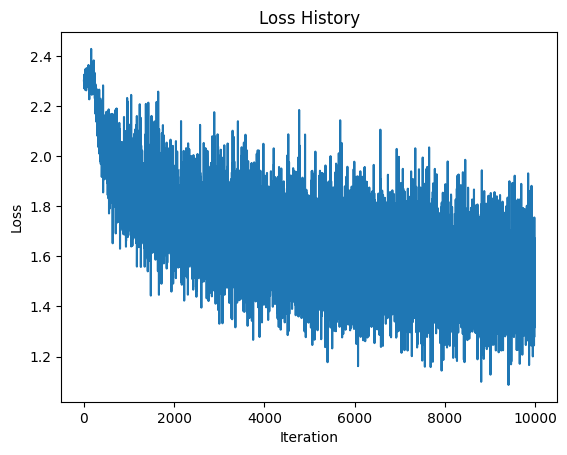

Training accuracy: 48.21%
Test accuracy: 45.59%


In [6]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# 1. Dataloading
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 50

trainset = torchvision.datasets.CIFAR10(root='./data', download=True,
                                        train=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data', download=True,
                                       train=False, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'deer', 'dog', 'frog', 'cat', 'horse', 'ship', 'truck')

# 2. Define Network Parameters
Din = 3 * 32 * 32  # Input size (flattened CIFAR-10 image size)
nodes = 100
K = 10  # Output size (number of classes in CIFAR-10)
std = 1e-5  # Initialize weights and biases
w1 = torch.randn(Din, nodes) * std
b1 = torch.zeros(nodes)

w2 = torch.randn(nodes, K) * std
b2 = torch.zeros(K)

# Hyperparameters
iterations = 10
lr = 8e-2  # Learning rate
lr_decay = 0.9  # Learning rate decay
reg = 0  # Regularization
loss_history = []

# 3. Training Loop
for t in range(iterations):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # Get inputs and labels
        inputs, labels = data
        Ntr = inputs.shape[0]  # Batch size
        x_train = inputs.view(Ntr, -1)  # Flatten input to (Ntr, Din)
        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        a_0 = x_train.mm(w1) + b1
        a_1 = torch.sigmoid(a_0)
        z = a_1.mm(w2) + b2
        z_max = torch.max(z, dim=-1, keepdim=True).values
        y_pred = torch.exp(z-z_max)/torch.sum(torch.exp(z-z_max), dim=-1, keepdim=True)

        loss = -(1 / Ntr) * torch.sum(y_train_onehot * torch.log(y_pred + 1e-15)) + reg * (torch.sum(w1 ** 2) + torch.sum(w2 ** 2))

        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        dz = (1.0 / Ntr) * (y_pred - y_train_onehot)

        dw2 = a_1.t().mm(dz) + 2.0 * reg * w2
        db2 = dz.sum(dim=0)
        
        da_1 = dz.mm(w2.t())
        da_0 = da_1 * a_1 * (1.0 - a_1)

        dw1 = x_train.t().mm(da_0) + 2.0 * reg * w1
        db1 = da_0.sum(dim=0)

        # Parameter update
        w2 -= lr * dw2
        b2 -= lr * db2
        w1 -= lr * dw1
        b1 -= lr * db1

    # Print loss for every epoch
    if t % 1 == 0:
        print(f"Epoch {t + 1}/{iterations}, Loss: {running_loss / len(trainloader)}")

    # Learning rate decay
    lr *= lr_decay

# 4. Plotting the Loss History
plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

# 5. Calculate Accuracy on Training Set
correct_train = 0
total_train = 0
with torch.no_grad():
    for data in trainloader:
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)
        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        a_0 = x_train.mm(w1) + b1
        a_1 = torch.sigmoid(a_0)
        z = a_1.mm(w2) + b2
        z_max = torch.max(z, dim =-1, keepdim=True).values
        y_train_pred = torch.exp(z-z_max)/torch.sum(torch.exp(z-z_max), dim=-1, keepdim=True)
        
        predicted_train = torch.argmax(y_train_pred, dim=1)
        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()

train_acc = 100 * correct_train / total_train
print(f"Training accuracy: {train_acc:.2f}%")

# 6. Calculate Accuracy on Test Set
correct_test = 0
total_test = 0
with torch.no_grad():
    for data in testloader:
        inputs, labels = data
        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)
        y_test_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        a_0 = x_test.mm(w1) + b1 
        a_1 = torch.sigmoid(a_0)
        z = a_1.mm(w2) + b2
        z_max = torch.max(z, dim = -1, keepdim=True).values
        y_test_pred = torch.exp(z-z_max)/torch.sum(torch.exp(z-z_max), dim = -1, keepdim=True)
        
        predicted_test = torch.argmax(y_test_pred, dim=1)
        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()

test_acc = 100 * correct_test / total_test
print(f"Test accuracy: {test_acc:.2f}%")